Load the data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("diamonds.csv")

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (53940, 11)

Columns: ['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

Missing values:
Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64


In [ ]:
display(df.head())



,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [ ]:
display(df.describe())

,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


Preprocessing

In [ ]:
# Remove unnecessary index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore")


In [ ]:
# Remove rows with invalid diamond dimensions
df = df[
    (df["x"] > 0) &
    (df["y"] > 0) &
    (df["z"] > 0)
].copy()

In [ ]:
# Remove any remaining missing values
df = df.dropna()

In [ ]:
print("Shape after cleaning:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
display(df.head())

Shape after cleaning: (53920, 10)

Missing values: 0


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


EDA

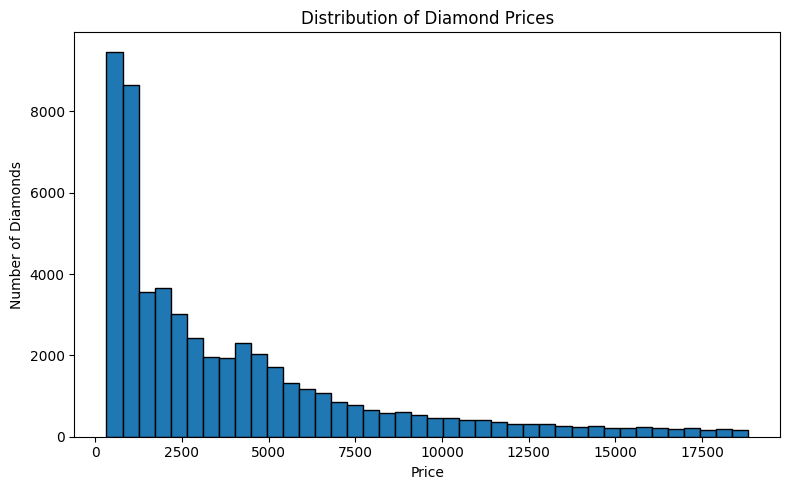

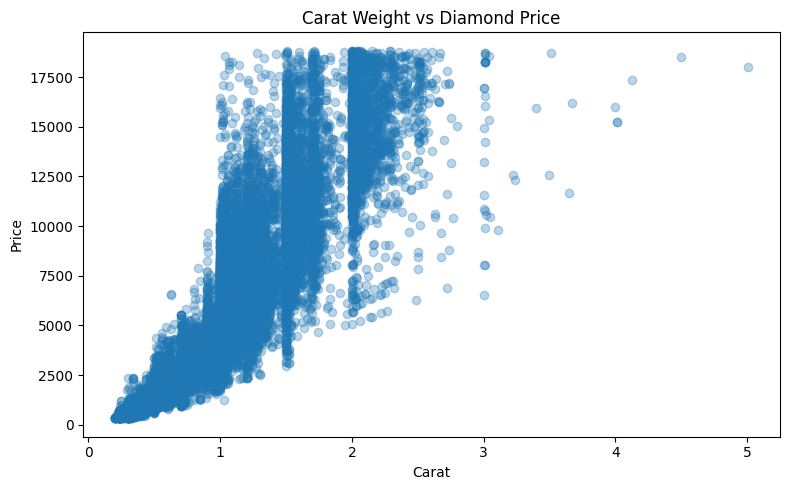

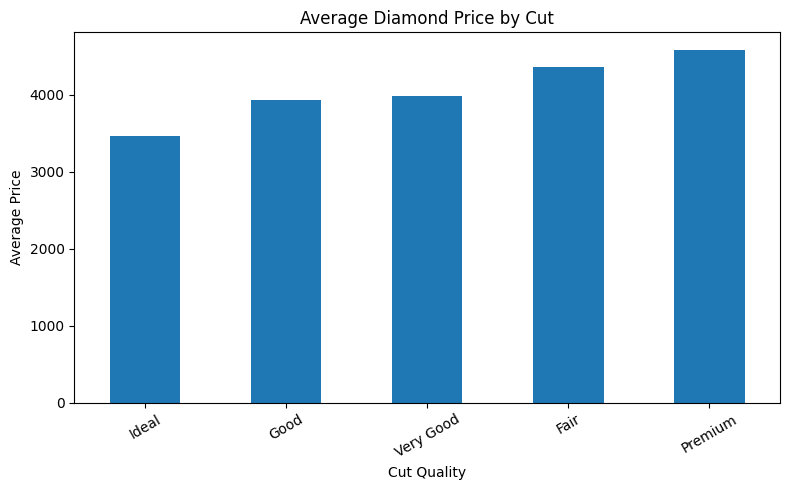

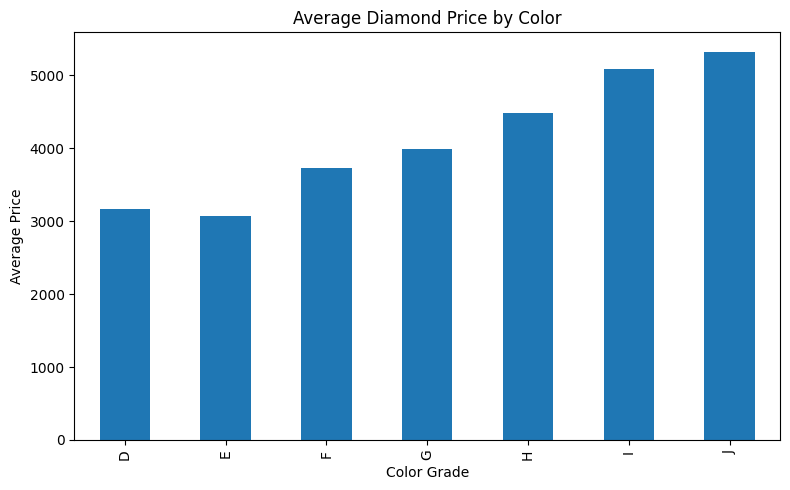

In [ ]:

# Distribution of diamond prices
plt.figure(figsize=(8, 5))
plt.hist(df["price"], bins=40, edgecolor="black")
plt.title("Distribution of Diamond Prices")
plt.xlabel("Price")
plt.ylabel("Number of Diamonds")
plt.tight_layout()
plt.show()

# Carat versus price
plt.figure(figsize=(8, 5))
plt.scatter(df["carat"], df["price"], alpha=0.3)
plt.title("Carat Weight vs Diamond Price")
plt.xlabel("Carat")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

# Average price by cut quality
cut_prices = df.groupby("cut")["price"].mean().sort_values()

cut_prices.plot(kind="bar", figsize=(8, 5))
plt.title("Average Diamond Price by Cut")
plt.xlabel("Cut Quality")
plt.ylabel("Average Price")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Average price by color
df.groupby("color")["price"].mean().plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Average Diamond Price by Color")
plt.xlabel("Color Grade")
plt.ylabel("Average Price")
plt.tight_layout()
plt.show()


Features and Target

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

X = df.drop(columns=["price"])
y = df["price"]

categorical_features = ["cut", "color", "clarity"]
numerical_features = [
    "carat", "depth", "table", "x", "y", "z"
]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Features:", X.columns.tolist())


Total samples: 53920
Training samples: 43136
Testing samples: 10784
Features: ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z']


Encode categorical features and scale numerical features

In [ ]:

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Encode categorical columns
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_cat = encoder.fit_transform(X_train[categorical_features])
X_test_cat = encoder.transform(X_test[categorical_features])

encoded_columns = encoder.get_feature_names_out(categorical_features)

X_train_cat = pd.DataFrame(
    X_train_cat, columns=encoded_columns, index=X_train.index
)
X_test_cat = pd.DataFrame(
    X_test_cat, columns=encoded_columns, index=X_test.index
)

# Scale numerical columns
scaler = StandardScaler()

X_train_num = pd.DataFrame(
    scaler.fit_transform(X_train[numerical_features]),
    columns=numerical_features,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    scaler.transform(X_test[numerical_features]),
    columns=numerical_features,
    index=X_test.index
)

# Combine numerical and encoded categorical features
X_train_processed = pd.concat([X_train_num, X_train_cat], axis=1)
X_test_processed = pd.concat([X_test_num, X_test_cat], axis=1)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
display(X_train_processed.head())


Training data shape: (43136, 26)
Testing data shape: (10784, 26)


,carat,depth,table,x,y,z,cut_Fair,cut_Good,cut_Ideal,cut_Premium,...,color_I,color_J,clarity_I1,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
50176,-0.521562,-0.172856,-0.654962,-0.420239,-0.388888,-0.431420,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
17688,1.060175,-1.082975,0.692117,1.178089,1.110219,0.998388,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
38203,-0.774640,0.107180,-1.103988,-0.697044,-0.818456,-0.749155,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1826,-0.163035,0.247199,0.692117,-0.036283,0.005614,0.016298,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
34543,-0.774640,0.317208,0.243091,-0.822053,-0.757089,-0.763597,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lr_model = LinearRegression()

lr_model.fit(X_train_processed, y_train)

lr_predictions = lr_model.predict(X_test_processed)

lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_mse = mean_squared_error(y_test, lr_predictions)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_predictions)

print("Multiple Linear Regression Results")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)


Multiple Linear Regression Results
MAE: 726.2998562075918
MSE: 1290368.1265477273
RMSE: 1135.943716276351
R2 Score: 0.9195127194882516


In [ ]:

from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_processed, y_train)

ridge_predictions = ridge_model.predict(X_test_processed)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_mse = mean_squared_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression Results")
print("MAE:", ridge_mae)
print("MSE:", ridge_mse)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)


Ridge Regression Results
MAE: 726.2735720823289
MSE: 1289247.2763164288
RMSE: 1135.4502526823571
R2 Score: 0.9195826330153468


In [ ]:

from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=0.01, max_iter=10000)

lasso_model.fit(X_train_processed, y_train)

lasso_predictions = lasso_model.predict(X_test_processed)

lasso_mae = mean_absolute_error(y_test, lasso_predictions)
lasso_mse = mean_squared_error(y_test, lasso_predictions)
lasso_rmse = np.sqrt(lasso_mse)
lasso_r2 = r2_score(y_test, lasso_predictions)

print("Lasso Regression Results")
print("MAE:", lasso_mae)
print("MSE:", lasso_mse)
print("RMSE:", lasso_rmse)
print("R2 Score:", lasso_r2)


Lasso Regression Results
MAE: 726.2793243332577
MSE: 1290015.1177376306
RMSE: 1135.7883243534557
R2 Score: 0.9195347385683396


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.037e+07, tolerance: 6.843e+07
  model = cd_fast.enet_coordinate_descent(


In [ ]:

from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=15,
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

dt_predictions = dt_model.predict(X_test_processed)

dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_mse = mean_squared_error(y_test, dt_predictions)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Results")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)


Decision Tree Results
MAE: 333.5815239732407
MSE: 445974.5284204231
RMSE: 667.813243669533
R2 Score: 0.9721821422650108


In [ ]:

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_test_processed)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


Random Forest Results
MAE: 273.5365694866405
MSE: 275295.53789497534
RMSE: 524.6861327450682
R2 Score: 0.9828283195110632


In [ ]:

from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor

bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=15,
        random_state=42
    ),
    n_estimators=20,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train_processed, y_train)

bagging_predictions = bagging_model.predict(X_test_processed)

bagging_mae = mean_absolute_error(y_test, bagging_predictions)
bagging_mse = mean_squared_error(y_test, bagging_predictions)
bagging_rmse = np.sqrt(bagging_mse)
bagging_r2 = r2_score(y_test, bagging_predictions)

print("Bagging Regression Results")
print("MAE:", bagging_mae)
print("MSE:", bagging_mse)
print("RMSE:", bagging_rmse)
print("R2 Score:", bagging_r2)


Bagging Regression Results
MAE: 276.69875202351204
MSE: 282728.9433853995
RMSE: 531.7226188393715
R2 Score: 0.9823646575679663


In [ ]:

results_df = pd.DataFrame([
    {
        "Model": "Multiple Linear Regression",
        "MAE": lr_mae, "MSE": lr_mse,
        "RMSE": lr_rmse, "R2 Score": lr_r2
    },
    {
        "Model": "Ridge Regression",
        "MAE": ridge_mae, "MSE": ridge_mse,
        "RMSE": ridge_rmse, "R2 Score": ridge_r2
    },
    {
        "Model": "Lasso Regression",
        "MAE": lasso_mae, "MSE": lasso_mse,
        "RMSE": lasso_rmse, "R2 Score": lasso_r2
    },
    {
        "Model": "Decision Tree",
        "MAE": dt_mae, "MSE": dt_mse,
        "RMSE": dt_rmse, "R2 Score": dt_r2
    },
    {
        "Model": "Random Forest",
        "MAE": rf_mae, "MSE": rf_mse,
        "RMSE": rf_rmse, "R2 Score": rf_r2
    },
    {
        "Model": "Bagging Regression",
        "MAE": bagging_mae, "MSE": bagging_mse,
        "RMSE": bagging_rmse, "R2 Score": bagging_r2
    }
]).sort_values("RMSE")

display(results_df.round(3))

print("Best model based on lowest RMSE:")
print(results_df.iloc[0]["Model"])


,Model,MAE,MSE,RMSE,R2 Score
4,Random Forest,273.537,275295.538,524.686,0.983
5,Bagging Regression,276.699,282728.943,531.723,0.982
3,Decision Tree,333.582,445974.528,667.813,0.972
1,Ridge Regression,726.274,1289247.276,1135.450,0.920
2,Lasso Regression,726.279,1290015.118,1135.788,0.920
0,Multiple Linear Regression,726.300,1290368.127,1135.944,0.920


Best model based on lowest RMSE:
Random Forest


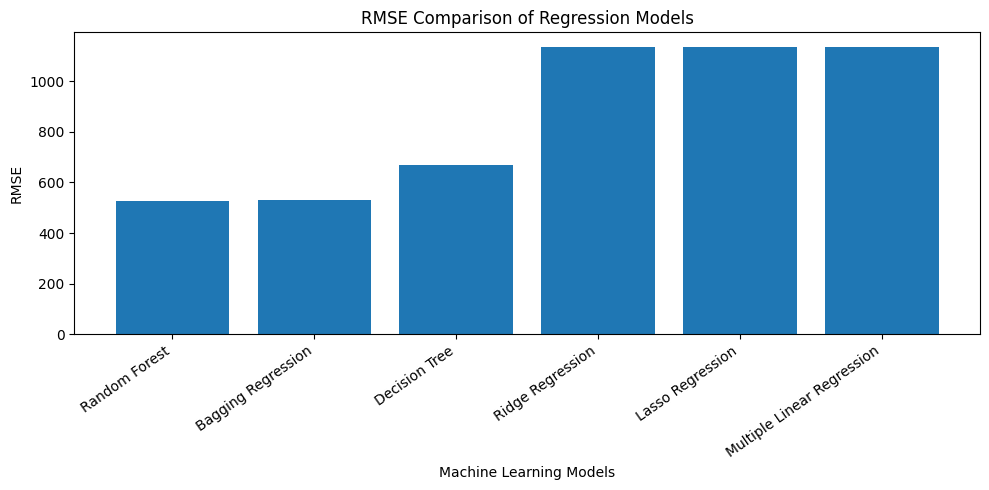

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


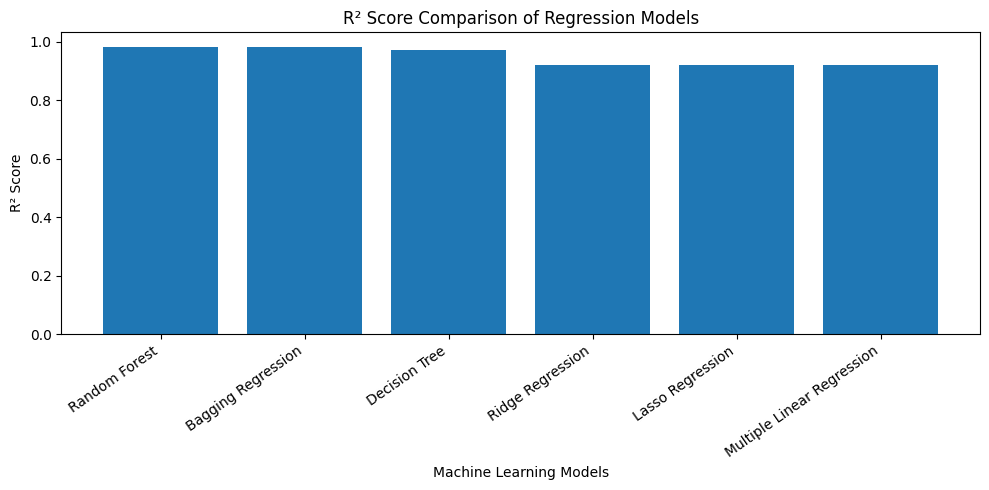

In [ ]:

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("R² Score Comparison of Regression Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R² Score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


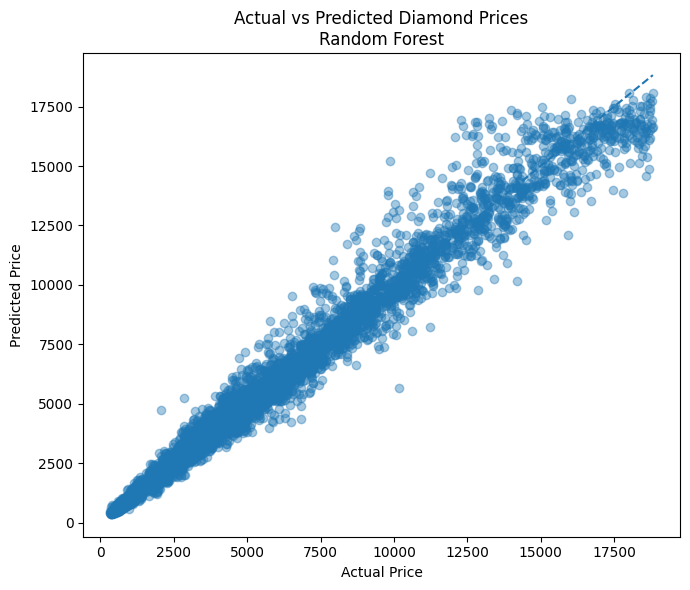

Best model: Random Forest


In [ ]:

best_model_name = results_df.iloc[0]["Model"]

model_dictionary = {
    "Multiple Linear Regression": lr_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Bagging Regression": bagging_model
}

best_model = model_dictionary[best_model_name]
best_predictions = best_model.predict(X_test_processed)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.4)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Diamond Prices\n{best_model_name}")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.tight_layout()
plt.show()

print("Best model:", best_model_name)


In [22]:

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_tuning = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 15, 20]
}

grid_search = GridSearchCV(
    estimator=rf_tuning,
    param_grid=param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_processed, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation RMSE:", -grid_search.best_score_)


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters: {'max_depth': 15, 'n_estimators': 100}
Best Cross-Validation RMSE: 571.6420435448501


In [23]:

tuned_rf = grid_search.best_estimator_
tuned_predictions = tuned_rf.predict(X_test_processed)

print("Tuned Random Forest Results")
print("MAE:", mean_absolute_error(y_test, tuned_predictions))
print("MSE:", mean_squared_error(y_test, tuned_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, tuned_predictions)))
print("R² Score:", r2_score(y_test, tuned_predictions))


Tuned Random Forest Results
MAE: 273.5365694866405
MSE: 275295.5378949753
RMSE: 524.6861327450681
R² Score: 0.9828283195110632


In [24]:

import joblib

original_best_rmse = results_df.iloc[0]["RMSE"]
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))

if tuned_rmse < original_best_rmse:
    final_model = tuned_rf
    final_model_name = "Tuned Random Forest"
else:
    final_model = model_dictionary[best_model_name]
    final_model_name = best_model_name

joblib.dump(final_model, "diamond_price_model.pkl")
joblib.dump(encoder, "diamond_encoder.pkl")
joblib.dump(scaler, "diamond_scaler.pkl")
joblib.dump(numerical_features, "diamond_numerical_features.pkl")
joblib.dump(categorical_features, "diamond_categorical_features.pkl")
joblib.dump(X_train_processed.columns.tolist(), "diamond_feature_columns.pkl")

print("Selected final model:", final_model_name)
print("Model and preprocessing files saved.")


Selected final model: Tuned Random Forest
Model and preprocessing files saved.


In [25]:

!pip install -q gradio joblib


In [26]:

import gradio as gr
import pandas as pd
import numpy as np
import joblib

# Load saved model and preprocessing objects
model = joblib.load("diamond_price_model.pkl")
encoder = joblib.load("diamond_encoder.pkl")
scaler = joblib.load("diamond_scaler.pkl")

numerical_features = joblib.load("diamond_numerical_features.pkl")
categorical_features = joblib.load("diamond_categorical_features.pkl")
feature_columns = joblib.load("diamond_feature_columns.pkl")


def predict_diamond_price(
    carat, cut, color, clarity, depth, table, x, y, z
):
    try:
        # Create input data
        input_df = pd.DataFrame([{
            "carat": carat,
            "cut": cut,
            "color": color,
            "clarity": clarity,
            "depth": depth,
            "table": table,
            "x": x,
            "y": y,
            "z": z
        }])

        # Scale numerical features
        numerical_data = scaler.transform(
            input_df[numerical_features]
        )

        numerical_df = pd.DataFrame(
            numerical_data,
            columns=numerical_features
        )

        # Encode categorical features
        categorical_data = encoder.transform(
            input_df[categorical_features]
        )

        encoded_columns = encoder.get_feature_names_out(
            categorical_features
        )

        categorical_df = pd.DataFrame(
            categorical_data,
            columns=encoded_columns
        )

        # Combine features in the exact training order
        processed_input = pd.concat(
            [numerical_df, categorical_df], axis=1
        )

        processed_input = processed_input.reindex(
            columns=feature_columns,
            fill_value=0
        )

        # Predict price
        predicted_price = float(model.predict(processed_input)[0])

        return f"Predicted Diamond Price: {predicted_price:,.2f}"

    except Exception as e:
        return f"Prediction error: {str(e)}"


# Build the interface
with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="sky",
        neutral_hue="slate"
    ),
    title="Diamond Price Predictor"
) as demo:

    gr.Markdown("""
    # 💎 Diamond Price Predictor
    ### Estimate a diamond's price using Machine Learning

    Enter the diamond's weight, quality grades, and dimensions below.
    """)

    with gr.Row():
        with gr.Column():
            carat = gr.Number(
                label="Carat Weight",
                value=0.5,
                minimum=0.01
            )
            cut = gr.Dropdown(
                choices=["Fair", "Good", "Very Good", "Premium", "Ideal"],
                label="Cut Quality",
                value="Ideal"
            )
            color = gr.Dropdown(
                choices=["D", "E", "F", "G", "H", "I", "J"],
                label="Color Grade",
                value="G"
            )
            clarity = gr.Dropdown(
                choices=["I1", "SI2", "SI1", "VS2", "VS1",
                         "VVS2", "VVS1", "IF"],
                label="Clarity Grade",
                value="VS1"
            )

        with gr.Column():
            depth = gr.Number(
                label="Depth Percentage",
                value=61.5,
                minimum=0.01
            )
            table = gr.Number(
                label="Table Percentage",
                value=57.0,
                minimum=0.01
            )
            x = gr.Number(
                label="Length (mm)",
                value=5.0,
                minimum=0.01
            )
            y = gr.Number(
                label="Width (mm)",
                value=5.0,
                minimum=0.01
            )
            z = gr.Number(
                label="Height (mm)",
                value=3.1,
                minimum=0.01
            )

    predict_button = gr.Button(
        "Predict Diamond Price 💎",
        variant="primary"
    )

    output = gr.Textbox(
        label="Prediction Result",
        interactive=False
    )

    predict_button.click(
        fn=predict_diamond_price,
        inputs=[
            carat, cut, color, clarity,
            depth, table, x, y, z
        ],
        outputs=output
    )

    gr.Markdown("""
    ---
    *This estimate is generated by a machine learning model
    trained on historical diamond data. It is not a guaranteed
    market price.*
    """)

demo.launch(share=True)


/tmp/ipykernel_14980/1407524377.py:77: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cb1d2473a7431989f8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
